# N150 — Do replay's paired health gains accumulate during sustained learning?

Execution authorized on 5 November 2026. The separate live status records progress.
Freeze implementation and engineering checks before scientific training.

## Question

N149 found that one replay update outperformed an equal-work current-image update
on subsequent recent-retention loss and RankMe in all six stream/history means.
Its continuation contained ordinary current-image updates, not repeated replay.
Repeated replay can change the state and optimizer dynamics, and its benefits
cannot be obtained by adding the one-update effects. Test the sustained action
before crediting a learned objective or predictor with its benefit.

Primary questions:
1. Does ongoing replay improve health compared with matched-work current-image
   training over a full ordered stream?
2. Does its benefit depend on frequent versus sparse training?
3. Are improvements in recent-history health accompanied by worse initial-context,
   older-bank, or unseen-future reconstruction/rank?

## Data and fixed schedules

Use N106 reserved clips [540:684], in three disjoint ordered streams of 48 clips
/ 4608 arrivals. These clips are unused by N145-N149; they are still from the
historically inspected dataset, not an untouched external benchmark. Verify
clip and pixel separation from earlier experiments and the old fixed audit bank.

Reserve arrivals 4544..4607 (64 images) as an untouched future-tail audit. No
method trains on or replays these images. All learners receive training-stream
arrivals 0..4543 in the same order, filling the first 255 arrivals without updates.

From the first 255 arrivals choose 64 initial-context audit images uniformly,
with fixed seeds 150101/150201/150301. Freeze these identities before the first
update. They never enter candidate training or replay, including via duplicate
pixels. They measure retained initial-context generalization; they are not a
representative sample of every later environment. Validate exact pixel separation
from subsequent training and tail-audit images before collection.

Two fixed schedules, with no health-dependent action decisions:
- Dense: update at every training arrival i >= 255; 4289 updates per learner.
- Sparse: update at i = 255 + 384*k, while i < 4544; 12 updates per learner.

Schedules are identical across methods within each stream/regime. Dense and sparse
are separate conditions, not compute-matched alternatives to one another.
Every learner restarts the same original full NN/Adam parent; no N149 learned
weights transfer. The first 255 arrivals and fixed parent are common references.

## Three methods per schedule

All positive actions use one Adam step at quarter nominal LR (2.5e-5), identical
clipping, decay, inherited moments and per-arrival first-view seeds.

1. Current-one: ordinary one-image update. This is the inexpensive reference.
2. Current-five: .5 times first current-view loss plus .5 times mean loss of four
   extra current-image views, in one gradient accumulation and one Adam step.
3. Replay-five: .5 times first current-view loss plus .5 times mean loss of four
   distinct past images, with otherwise identical weighting and optimizer work.

Current-five and Replay-five use the same first view and second-batch random
draws/shapes. Replay selects four distinct past-image identities uniformly from
the preceding 256 arrivals, excluding reserved audit pixels. Sampling uses
predeclared per-arrival seeds and cannot inspect health. All prior non-audit
arrivals are eligible, including originally skipped and warmup images. This is
causal bounded-window replay, not an optimized memory-selection policy.

Primary content contrast: Replay-five minus Current-five at equal optimizer
steps, learning-rate sequence and gradient-image work. Current-five minus
Current-one identifies extra-view effects; Replay-five versus Current-one shows
the practical benefit/cost tradeoff and must not be called compute-matched.

Three streams x two schedules x three methods = 18 sustained learner trajectories.
No neural-network action forks, rollback, online critic, objective tuning, or
threshold changes occur in scientific trajectories. Freeze all seeds and inputs.

## Health measurements and primary comparisons

Record fixed-mask reconstruction of each incoming image BEFORE any training on
it. Average over arrivals 255..4543 to measure prequential reconstruction. The
incoming identity was unavailable to past replay; verify duplicate-pixel rules.
Also record the SAME image after its scheduled action and its paired gain.
Never average only accepted images when comparing different schedules.

At the parent, every 384 training arrivals, and final arrival count 4544, measure:
- The reserved initial-context audit: reconstruction loss and RankMe.
- The older fixed N147-N149 audit bank: reconstruction loss, RankMe and other
  existing health signals for continuity and broader population sensitivity.
- The latest 256 received images: freshly re-encoded RankMe and reconstruction.
  This recent population may overlap training/replay; it is an operational health
  readout, not an independent generalization bank. Keep its interpretation distinct.

At the final learner state only, evaluate the 64 unseen future-tail images using
the same identities/masks across arms. Report loss and RankMe, plus the original
parent's corresponding readings. The future tail never controls selection,
stopping, hyperparameters or checkpoint choice.

Prespecified primary reporting for Replay-five versus Current-five, separately
within dense and sparse regimes:
- Final initial-context loss and RankMe, each as a paired difference.
- Final untouched future-tail loss and RankMe, each separately.
- Mean incoming pre-update reconstruction loss on identical arrival coverage.

Older-bank and recent-window trajectories and final values are key secondary
diagnostics. Show the full checkpoint trajectory and shared-checkpoint means;
never select a best checkpoint. Report all three stream-level differences and
their equally weighted mean. Do not combine loss and rank into a new winner score.
Do not count frames/checkpoints as independent replicates; parents are shared.

The historical-bank readouts may improve on one health metric and worsen on
another. Retain those tradeoffs, including when the primary local audit improves.
Also show gradients processed, optimizer steps, physical LR budgets, measurement
cost and elapsed training time. Five gradient images cost more than one even when
the number of optimizer steps is identical.

## Interpretation and decision

- Replay has consistent favorable health/adaptation effects under both schedules:
  sustained replay is a stronger baseline for the next learned-selector test.
  Subsequent mixed-objective control must beat it at matched work, rather than
  only beat current-image training.
- Replay wins mainly in one regime: its utility depends on learning history/dose.
  A later selector may need to identify when replay is useful; an unconditional
  replay claim is not supported.
- Recent retention improves but future-tail/prequential performance worsens:
  the retention/adaptation tradeoff is real and must enter the objective explicitly.
- Gains disappear or reverse with repeated replay: N149's one-action benefit
  does not transfer to a sustained policy. Investigate replay frequency/content
  before increasing predictor complexity.
- Current-five matches Replay-five over long trajectories: the sustained benefit
  is not established as past-content-specific despite the one-action diagnostic.

These are descriptive criteria, not formal significance gates. Small or mixed
effects across three reused-source streams remain inconclusive. This experiment
does not determine the best loss mixture, qualify a health predictor, or establish
downstream task performance. No task labels/probes/kNN/fine-tuning are used.

## Implementation requirements before launch

Reuse N149's verified update primitives without modifying its frozen files.
Verify exact ordinary-quarter equivalence, equal first/second RNG draws, one-step
Adam accounting, causal replay and audit exclusion. GPU preflight must cover all
three methods under uninterrupted versus resumed trajectories and true skips.

Freeze source/data/sample hashes before scientific learning. Save full model,
optimizer, RNG and trace with bounded checkpoint generations. Use the established
safe stop request, disk reserve and visible numerical-failure behavior. The next
notebook must include this protocol at the top and update current-image, recent,
initial-context, old-bank health and budget plots as the background queue runs.
Add the unseen-tail comparison only after the corresponding run is complete.


# N150 live results

Status: **complete**; updated UTC `2026-11-05T09:36:27.835461+00:00`. **18/18 trajectories complete.**

Active: preflight / engineering / checks, 0/4544 arrivals.

Positive comparison values favor the named candidate. Dense and sparse schedules are separate conditions. Current-five and Replay-five have matched gradient-image work; Current-one is a cheaper reference.

## stream_a / dense

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 4289 | 4289 | 0.824596 | 1.126319 | 1.905380 | 0.826566 | 1.222187 |
| current_five | 4544 | 4289 | 21445 | 0.823995 | 1.114194 | 2.253676 | 0.820161 | 1.211368 |
| replay_five | 4544 | 4289 | 21445 | 0.811667 | 0.923354 | 2.401669 | 0.827988 | 1.326834 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.190839 | +0.147993 |
| future_tail | -0.007827 | +0.115466 |
| historical | +0.090302 | +0.740708 |
| recent | +0.004974 | +0.175864 |

Mean incoming pre-update reconstruction advantage: **+0.012328**.

## stream_a / sparse

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 12 | 12 | 1.083972 | 1.213838 | 2.021182 | 0.862241 | 1.327117 |
| current_five | 4544 | 12 | 60 | 1.082526 | 1.208794 | 2.036961 | 0.862140 | 1.329194 |
| replay_five | 4544 | 12 | 60 | 1.081014 | 1.202627 | 2.038382 | 0.861682 | 1.330326 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.006167 | +0.001421 |
| future_tail | +0.000458 | +0.001132 |
| historical | +0.003453 | +0.005775 |
| recent | +0.001072 | +0.001987 |

Mean incoming pre-update reconstruction advantage: **+0.001512**.

## stream_b / dense

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 4289 | 4289 | 0.830030 | 0.832214 | 3.783930 | 0.931681 | 2.013420 |
| current_five | 4544 | 4289 | 21445 | 0.831250 | 0.823796 | 3.326367 | 0.931363 | 2.136241 |
| replay_five | 4544 | 4289 | 21445 | 0.817679 | 0.811013 | 3.900890 | 0.914872 | 1.844607 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.012782 | +0.574523 |
| future_tail | +0.016491 | -0.291634 |
| historical | +0.021643 | +0.284020 |
| recent | +0.027704 | +0.526450 |

Mean incoming pre-update reconstruction advantage: **+0.013571**.

## stream_b / sparse

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 12 | 12 | 1.075881 | 1.148686 | 2.749398 | 1.185851 | 1.689401 |
| current_five | 4544 | 12 | 60 | 1.075655 | 1.148589 | 2.751707 | 1.185967 | 1.692223 |
| replay_five | 4544 | 12 | 60 | 1.072096 | 1.134208 | 2.753477 | 1.171282 | 1.691356 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.014381 | +0.001770 |
| future_tail | +0.014684 | -0.000867 |
| historical | +0.009004 | -0.000551 |
| recent | +0.000354 | +0.008360 |

Mean incoming pre-update reconstruction advantage: **+0.003559**.

## stream_c / dense

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 4289 | 4289 | 0.805293 | 0.746527 | 2.522597 | 0.508916 | 1.151989 |
| current_five | 4544 | 4289 | 21445 | 0.803197 | 0.714046 | 2.658827 | 0.500984 | 1.177769 |
| replay_five | 4544 | 4289 | 21445 | 0.790417 | 0.712261 | 3.169373 | 0.483789 | 1.303532 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.001785 | +0.510546 |
| future_tail | +0.017195 | +0.125763 |
| historical | +0.032385 | +1.698228 |
| recent | +0.063256 | +0.870762 |

Mean incoming pre-update reconstruction advantage: **+0.012780**.

## stream_c / sparse

Matched-work verification: True.

| Method | Arrivals | Updates | Gradient images | Mean incoming pre-update loss | Initial loss | Initial RankMe | Future-tail loss | Future-tail RankMe |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| current_one | 4544 | 12 | 12 | 1.091590 | 1.310407 | 2.914840 | 1.372793 | 1.277987 |
| current_five | 4544 | 12 | 60 | 1.091716 | 1.310484 | 2.930990 | 1.373891 | 1.280650 |
| replay_five | 4544 | 12 | 60 | 1.089268 | 1.296693 | 2.914606 | 1.354918 | 1.277828 |

Partial rows have different arrival coverage; comparisons below wait for complete matched runs. Tail images are evaluated only at the final state.

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.013791 | -0.016384 |
| future_tail | +0.018973 | -0.002823 |
| historical | +0.005918 | +0.002244 |
| recent | +0.000209 | +0.005445 |

Mean incoming pre-update reconstruction advantage: **+0.002447**.

## Completed three-stream mean: dense

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.068469 | +0.411021 |
| future_tail | +0.008620 | -0.016802 |
| historical | +0.048110 | +0.907652 |
| recent | +0.031978 | +0.524359 |

Incoming pre-update loss advantage: +0.012893.

## Completed three-stream mean: sparse

| Replay minus Current-five | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.011446 | -0.004398 |
| future_tail | +0.011372 | -0.000853 |
| historical | +0.006125 | +0.002489 |
| recent | +0.000545 | +0.005264 |

Incoming pre-update loss advantage: +0.002506.

Three stream differences are descriptive paired evidence with a shared original parent. Initial, old, recent and future populations can disagree. No health score, task labels, predictor, best-checkpoint selection or threshold tuning is used.


In [1]:
from pathlib import Path
from IPython.display import display, Image
RUN = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\sustained-health-replay\\20261105-n150')


### Actual incoming-image loss and embedding health


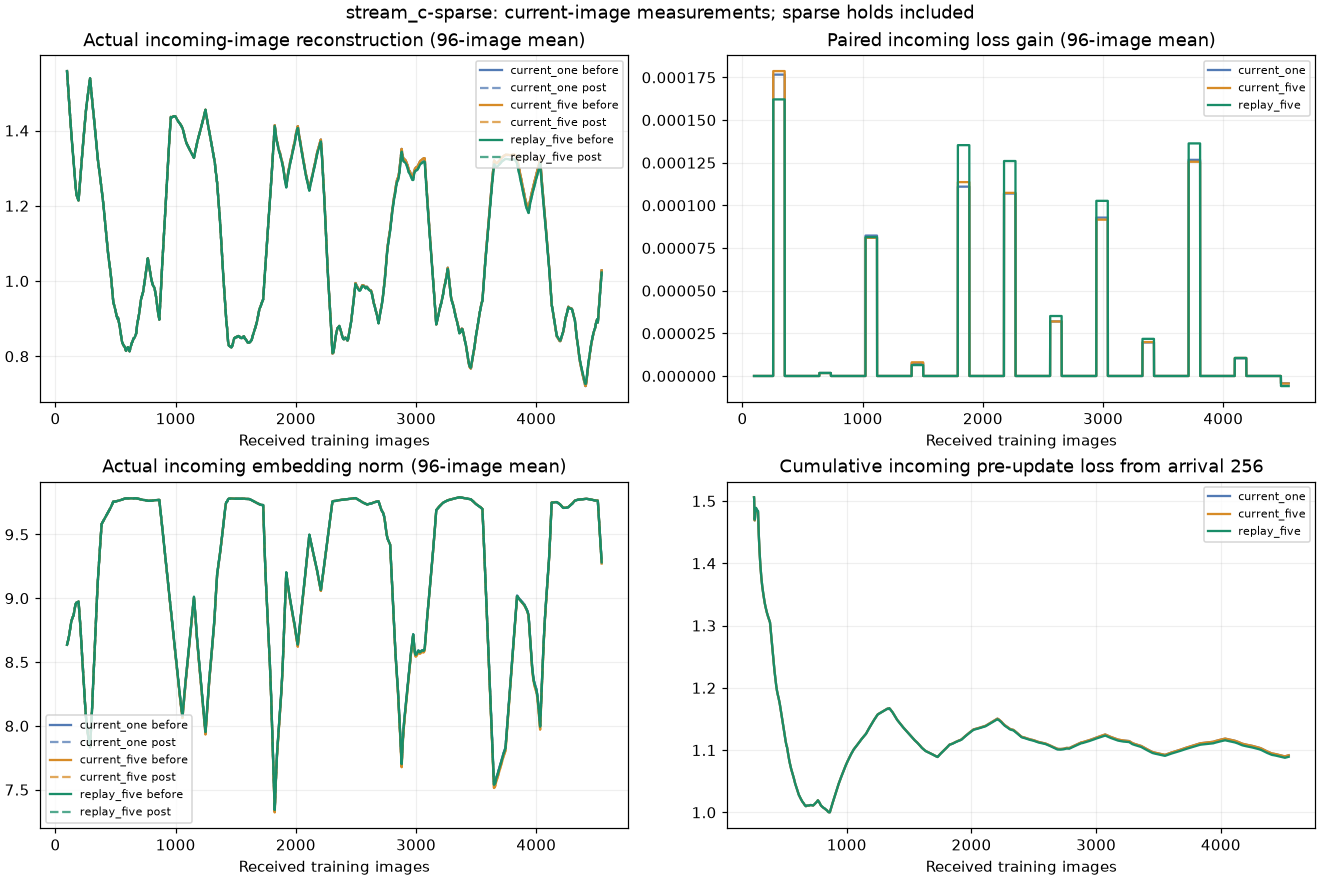

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-incoming-health.png')))


### Initial-context, older-bank and recent-window health


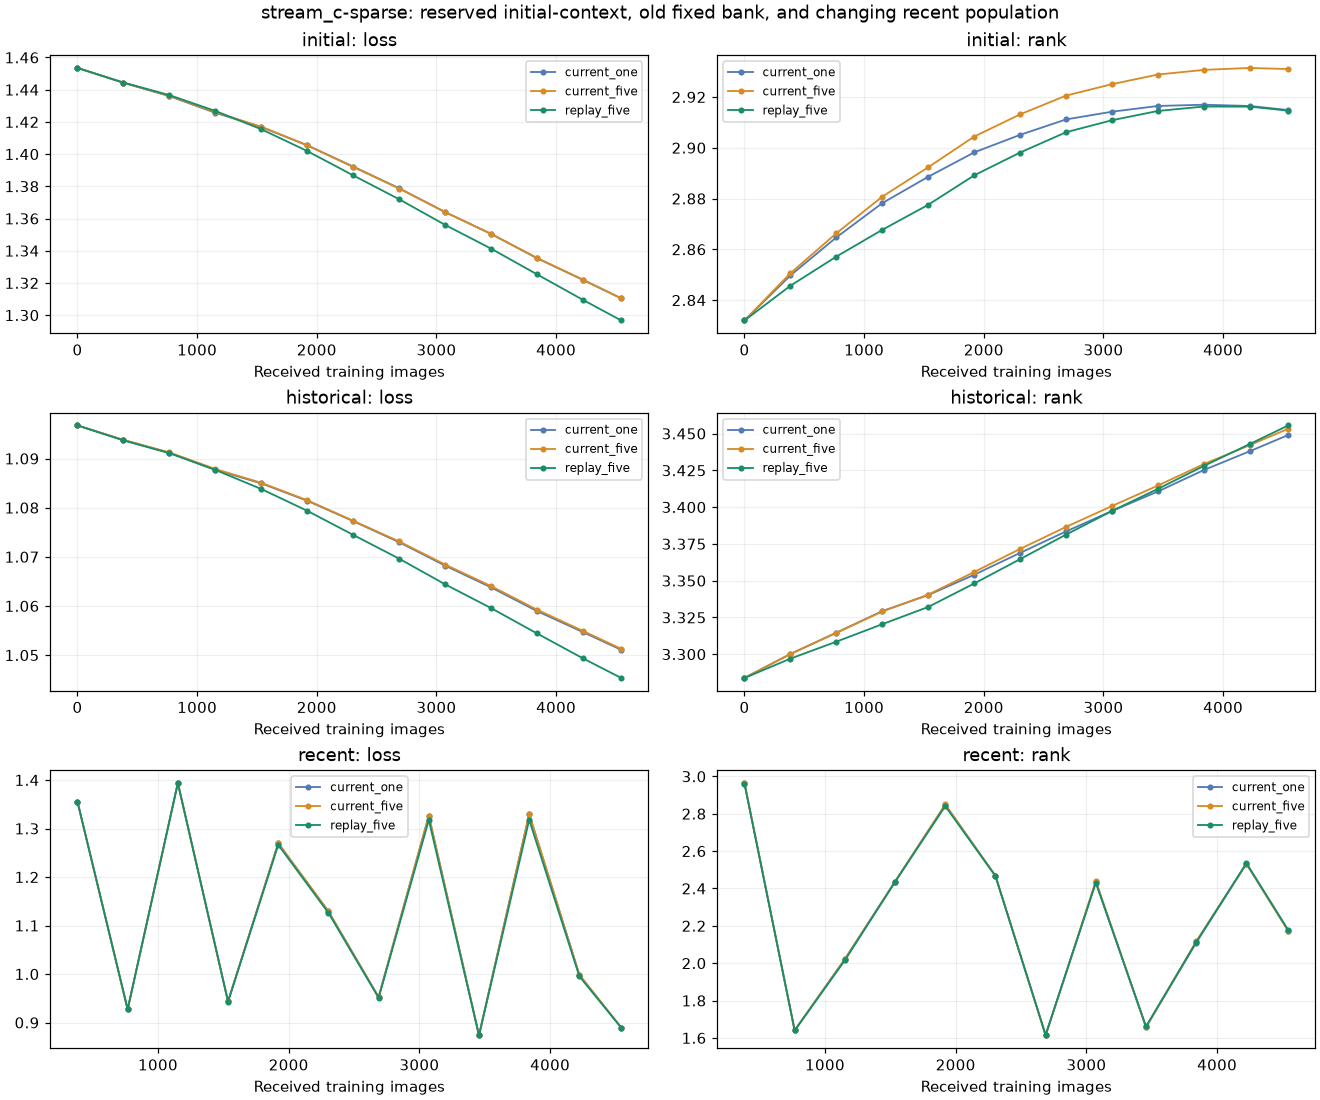

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-audit-health.png')))


### Training work and schedule matching


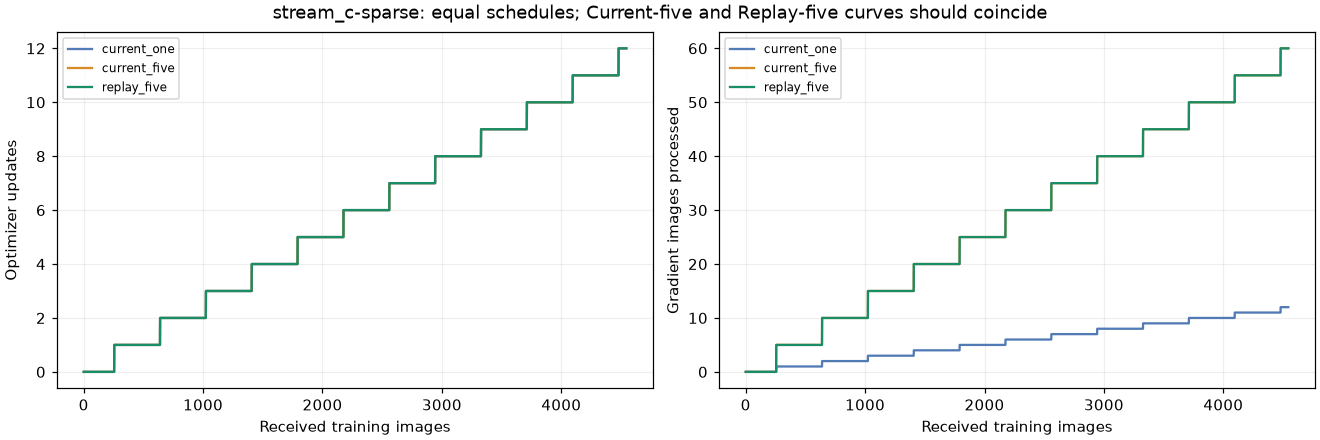

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-budgets.png')))


### Untouched future-tail evaluation


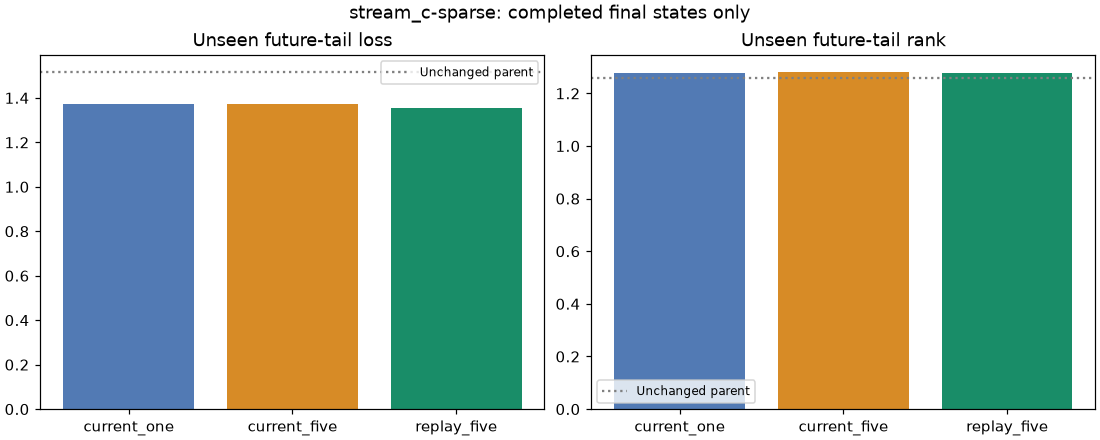

In [1]:
display(Image(filename=str(RUN / 'stream_c-sparse-future-tail.png')))


### stream_a / dense: incoming-health (completed)
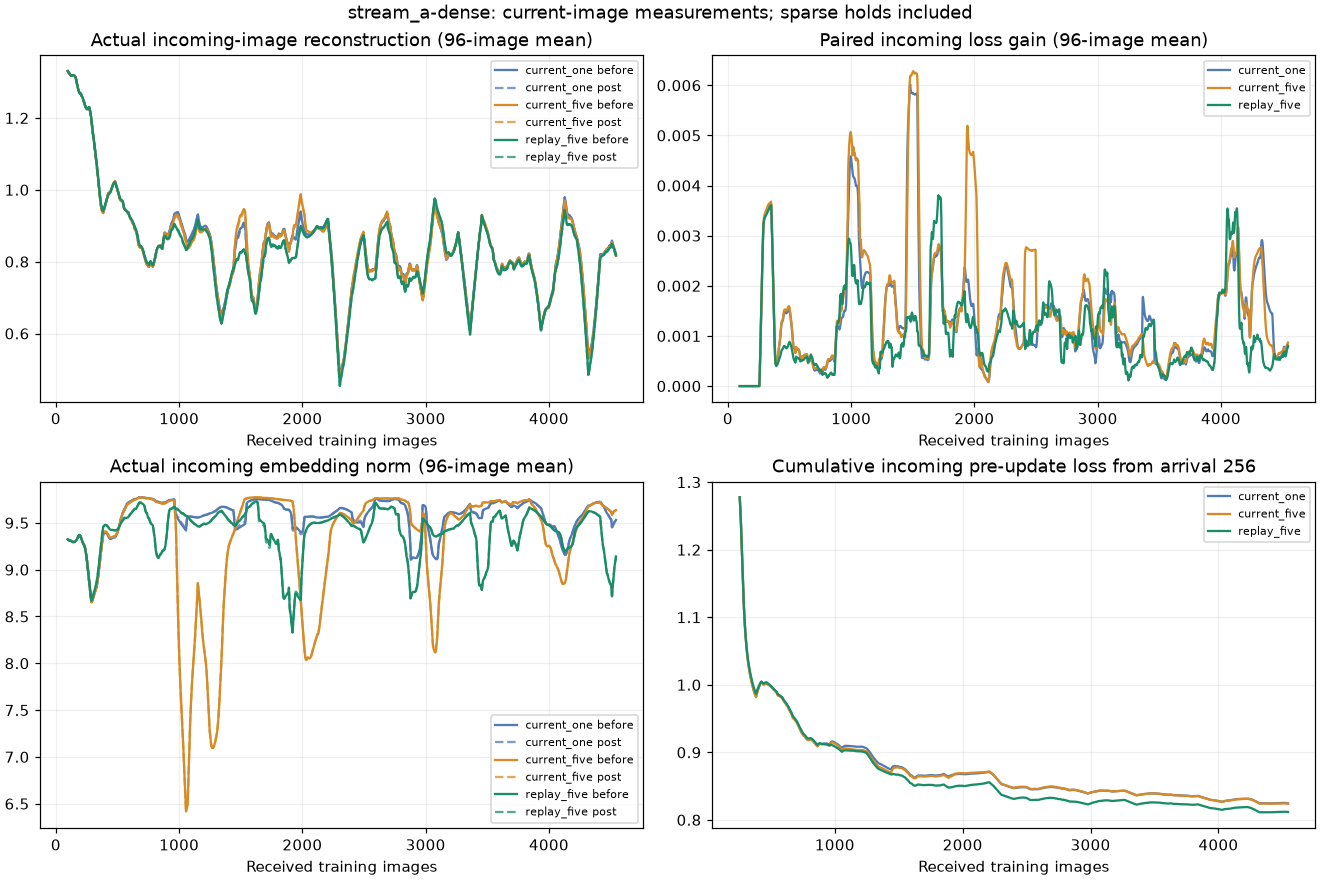

### stream_a / dense: audit-health (completed)
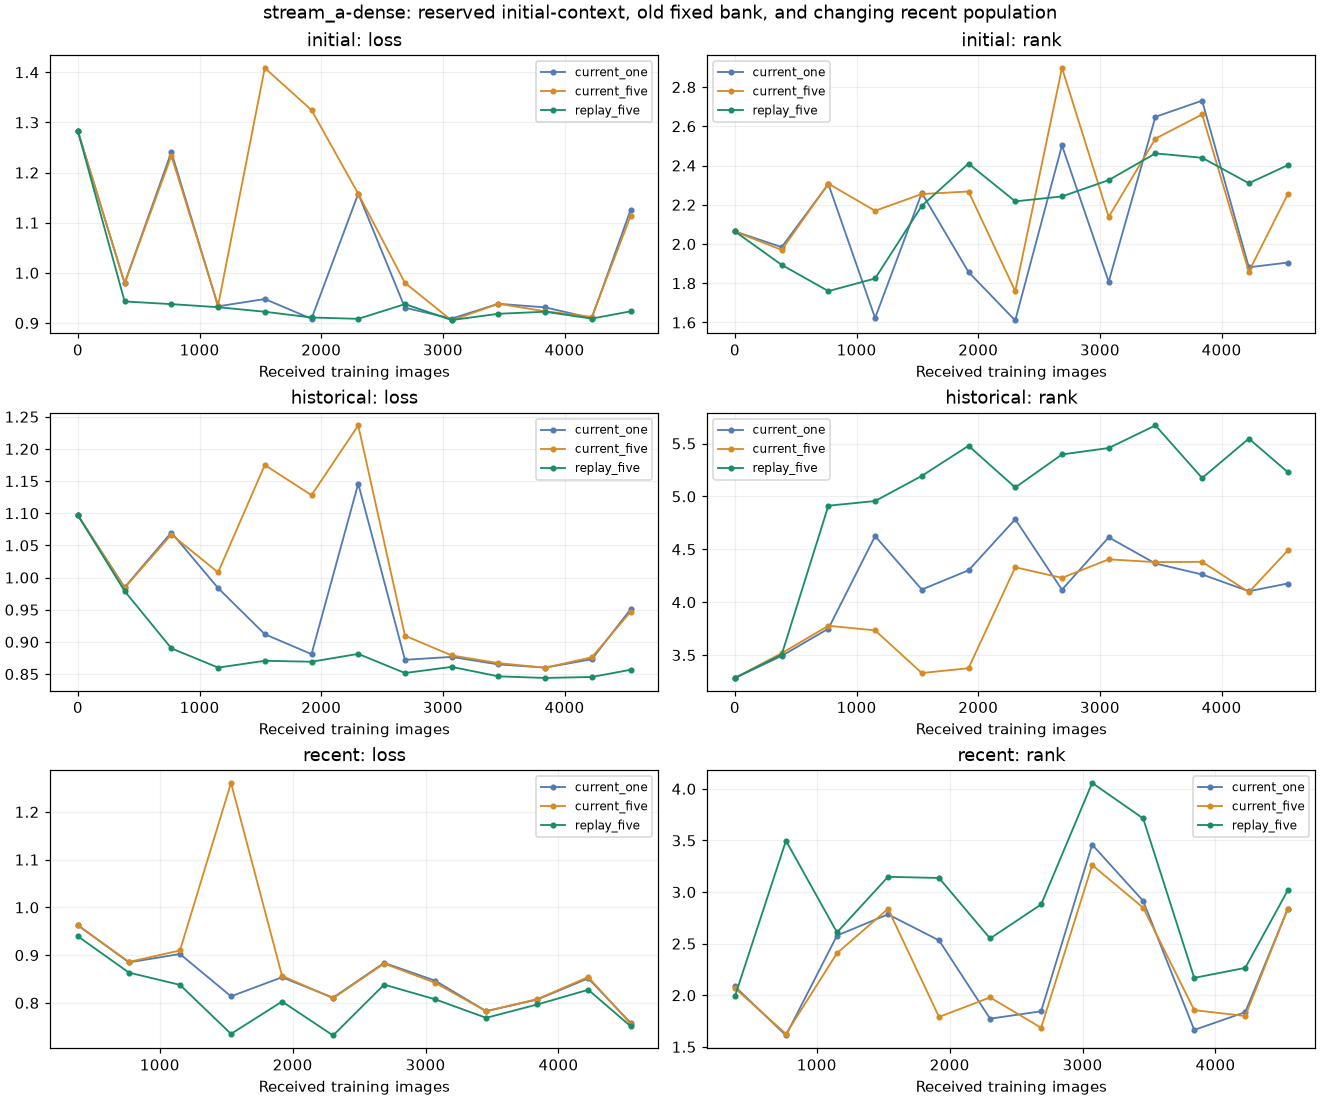

### stream_a / dense: budgets (completed)
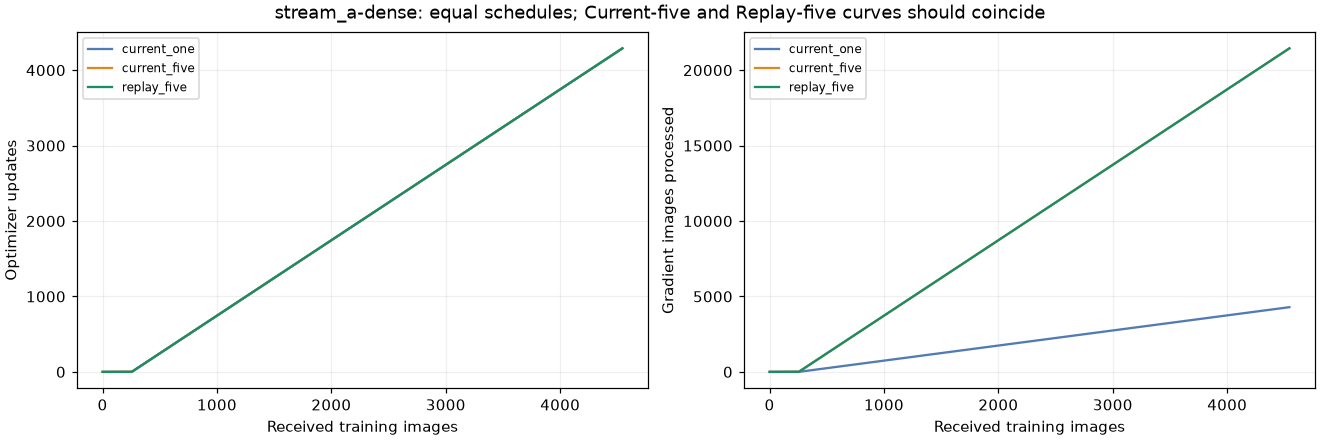

### stream_a / dense: future-tail (completed)
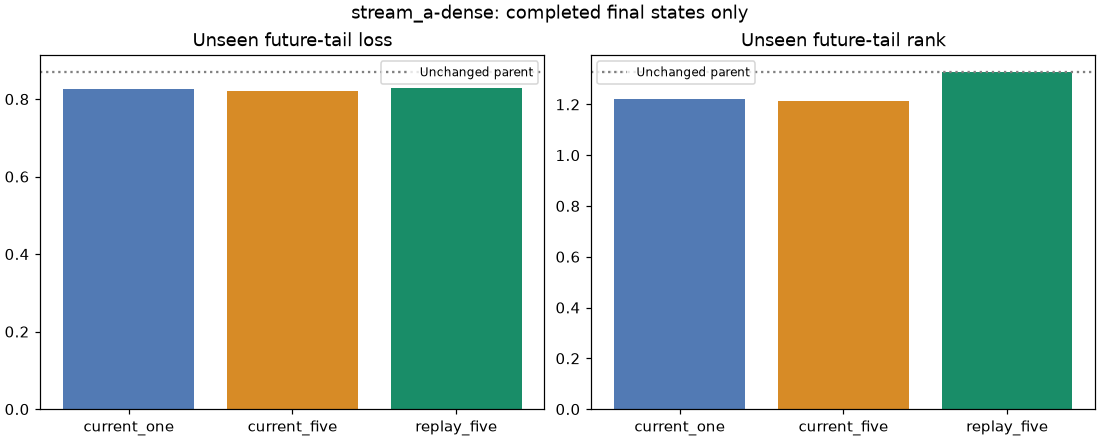

### stream_a / sparse: incoming-health (completed)
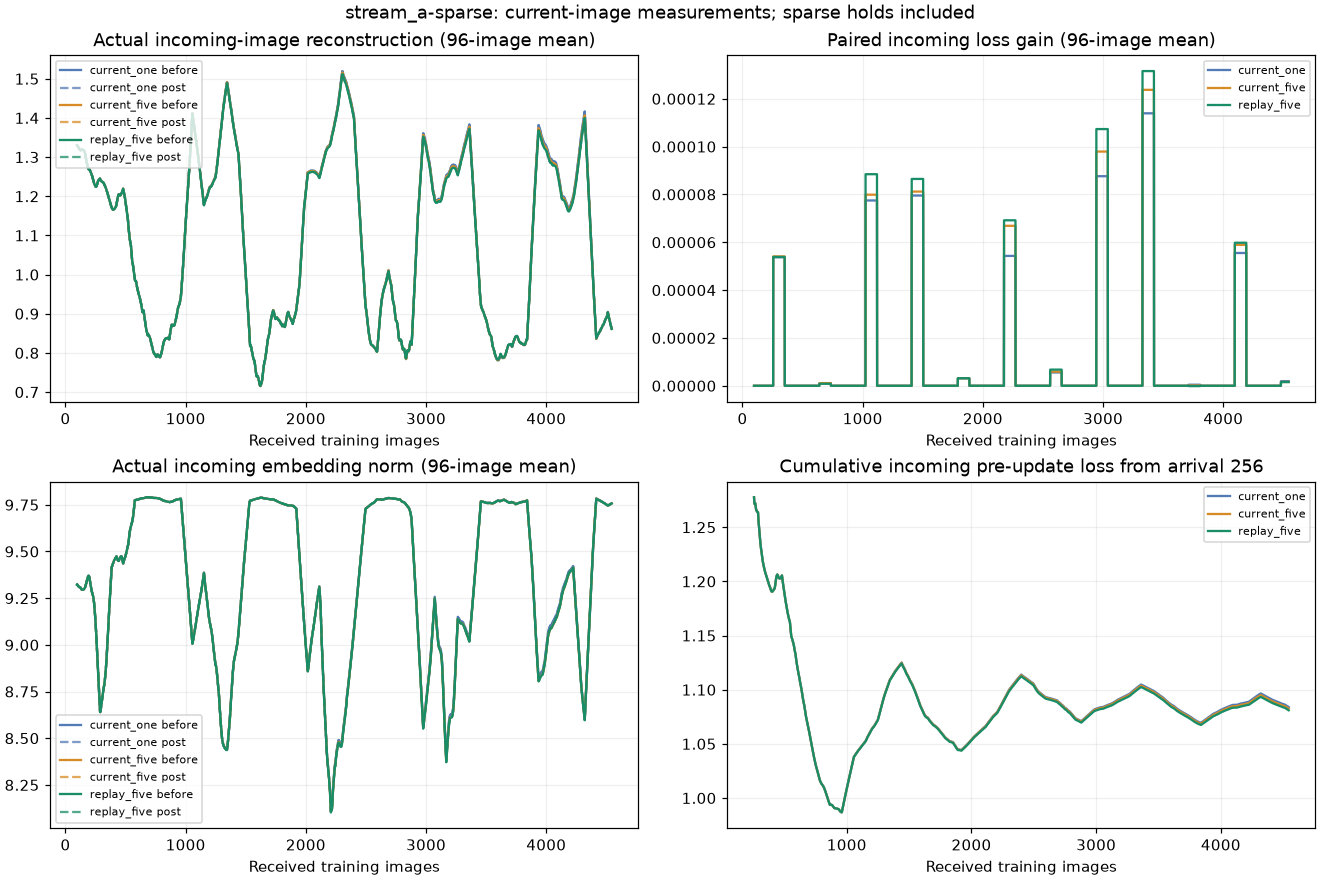

### stream_a / sparse: audit-health (completed)
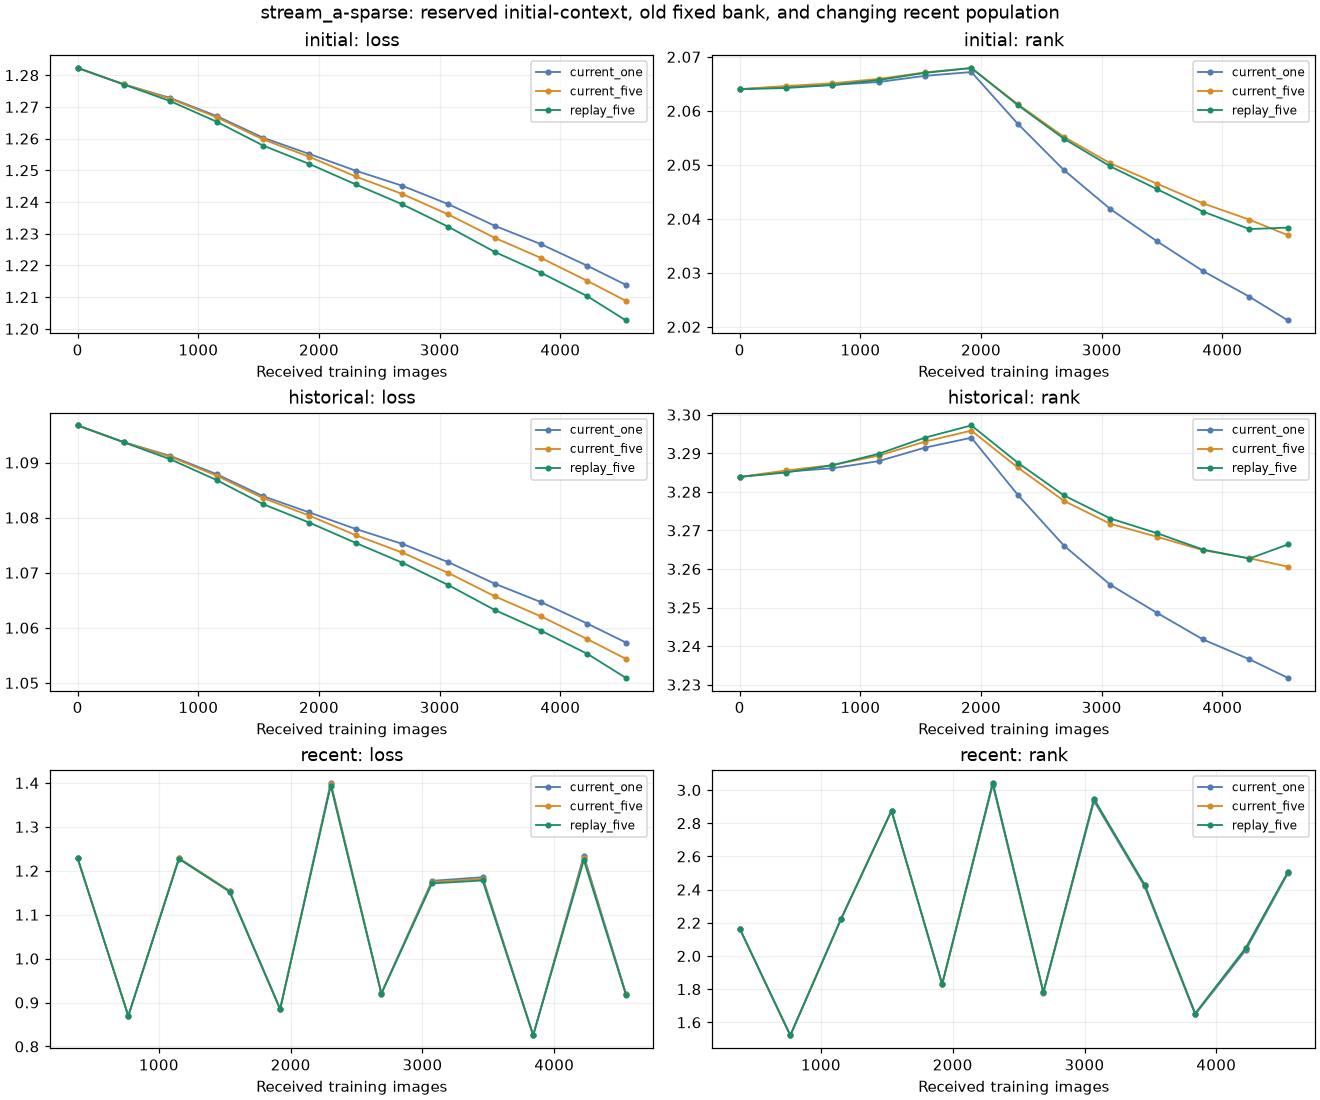

### stream_a / sparse: budgets (completed)
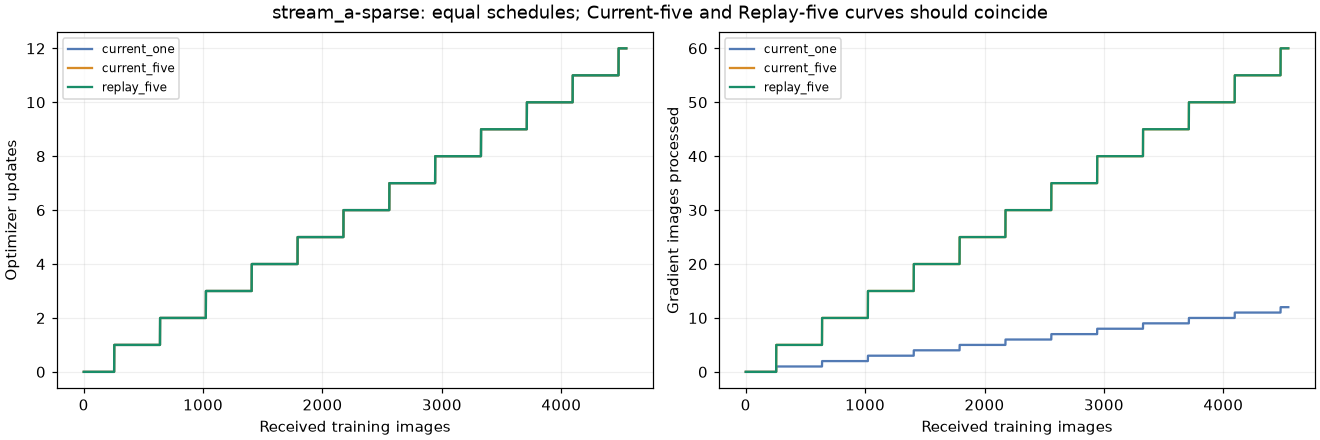

### stream_a / sparse: future-tail (completed)
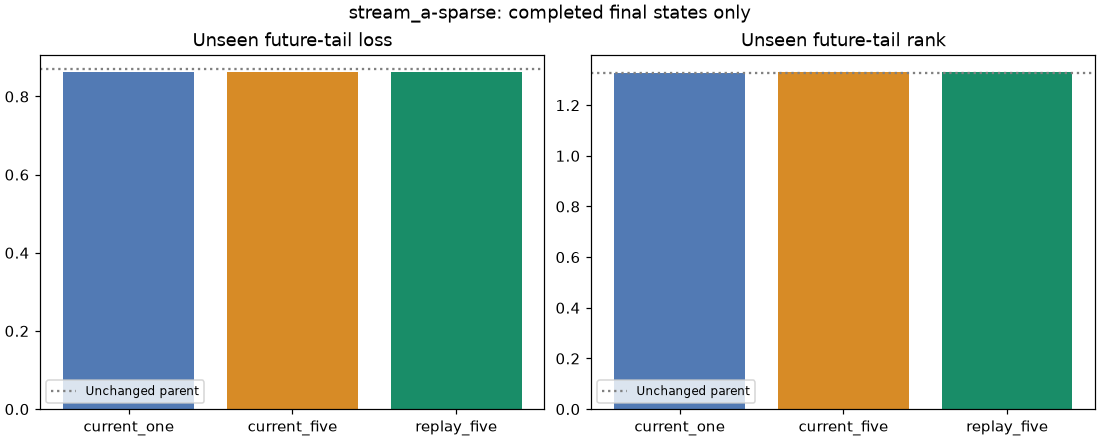

### stream_b / dense: incoming-health (completed)
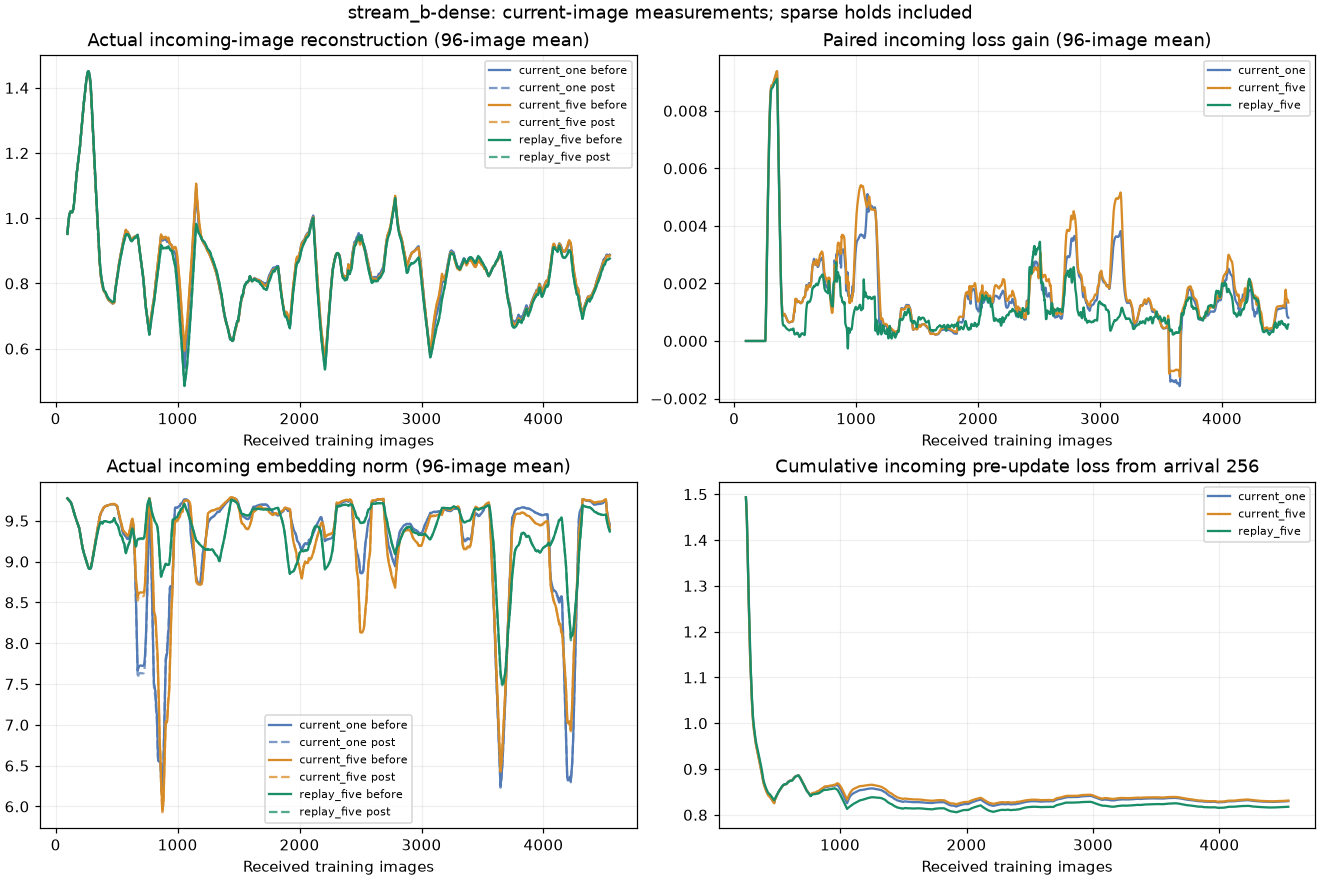

### stream_b / dense: audit-health (completed)
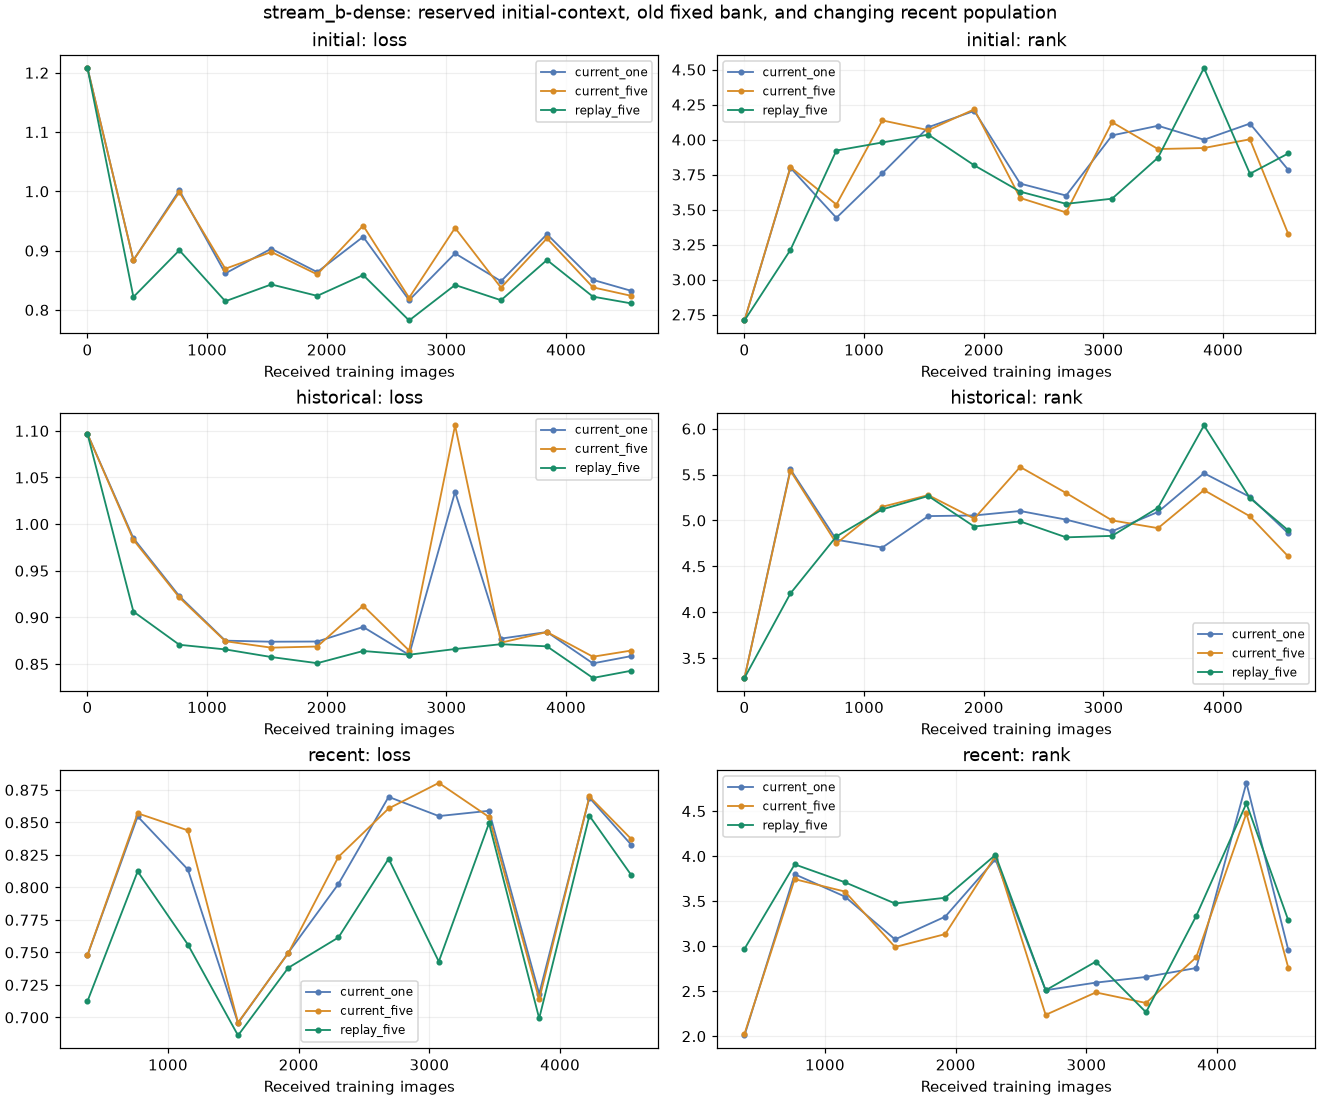

### stream_b / dense: budgets (completed)
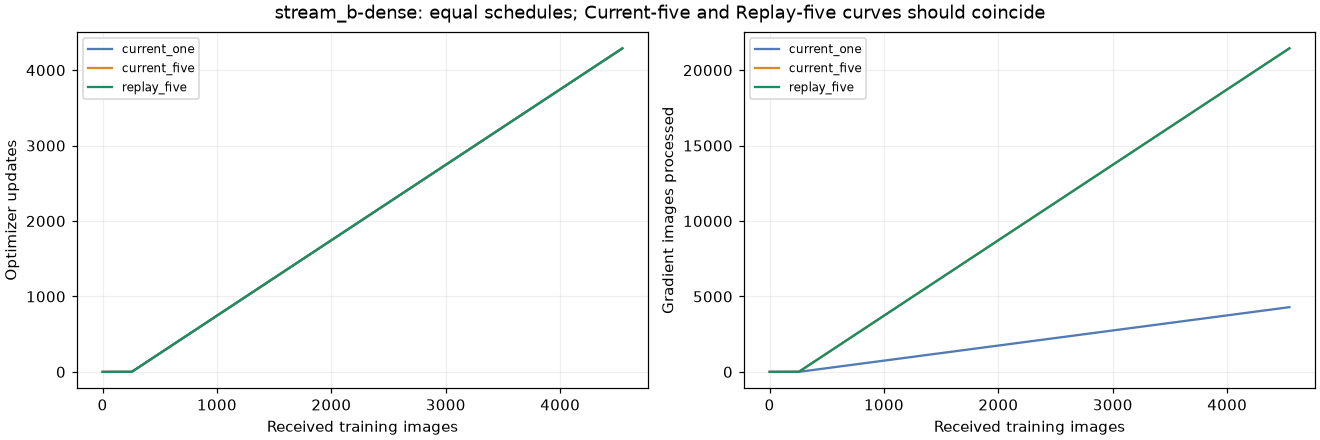

### stream_b / dense: future-tail (completed)
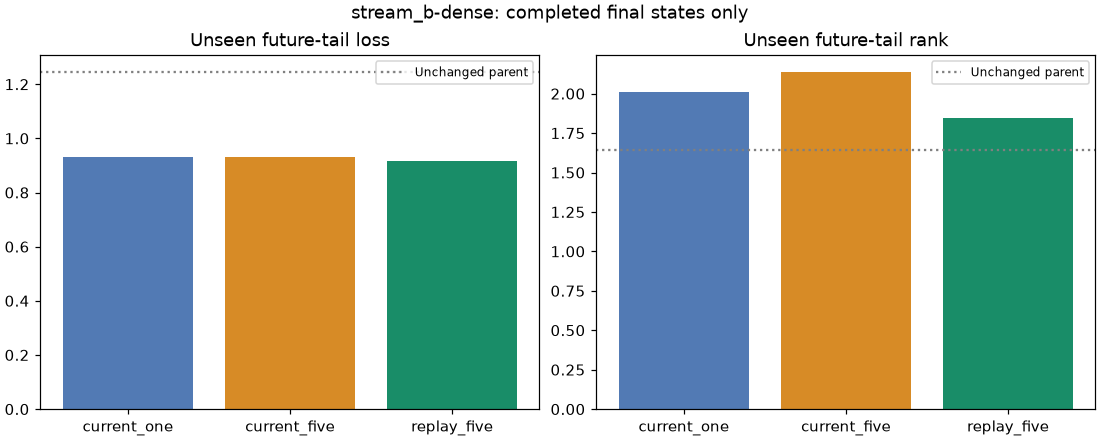

### stream_b / sparse: incoming-health (completed)
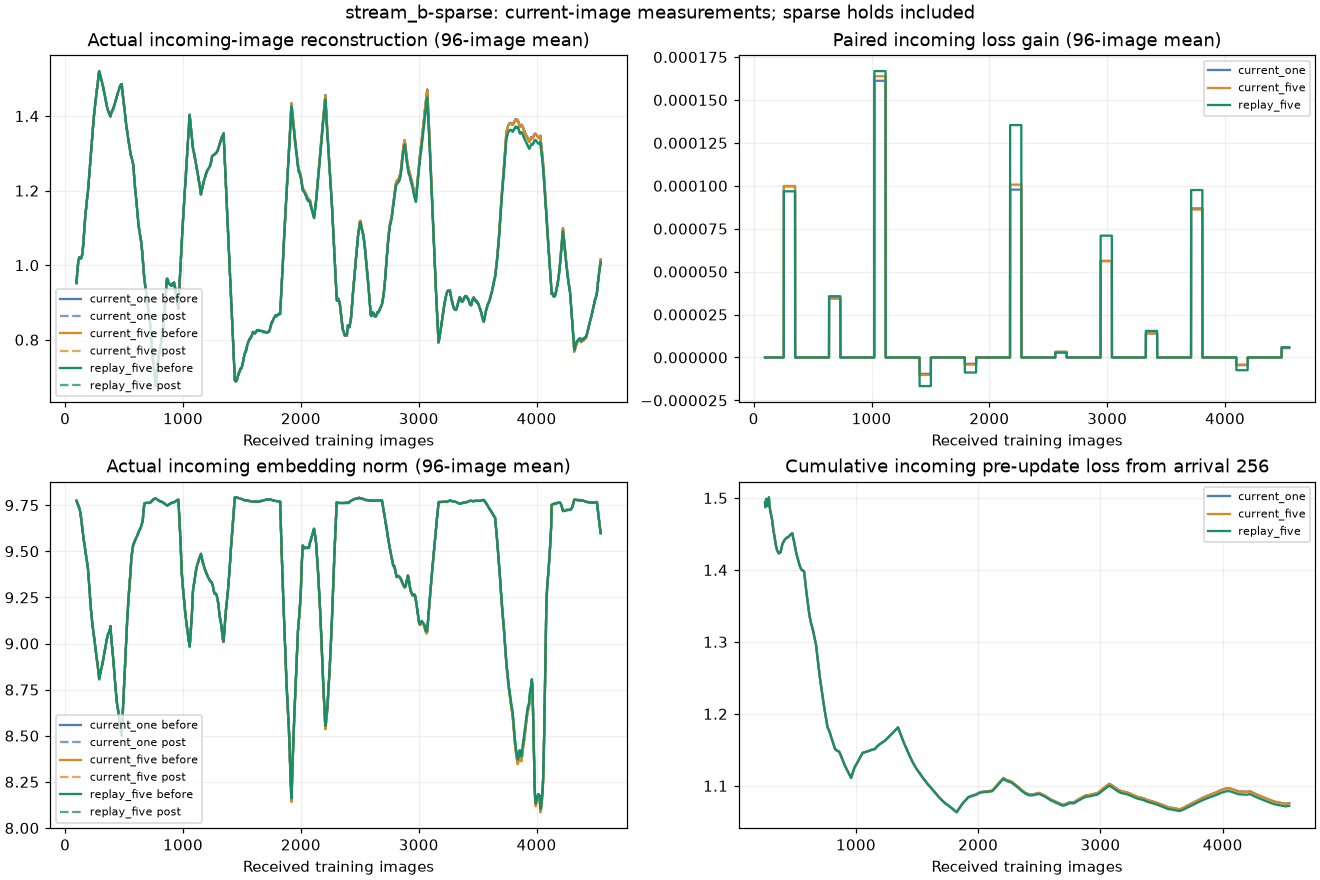

### stream_b / sparse: audit-health (completed)
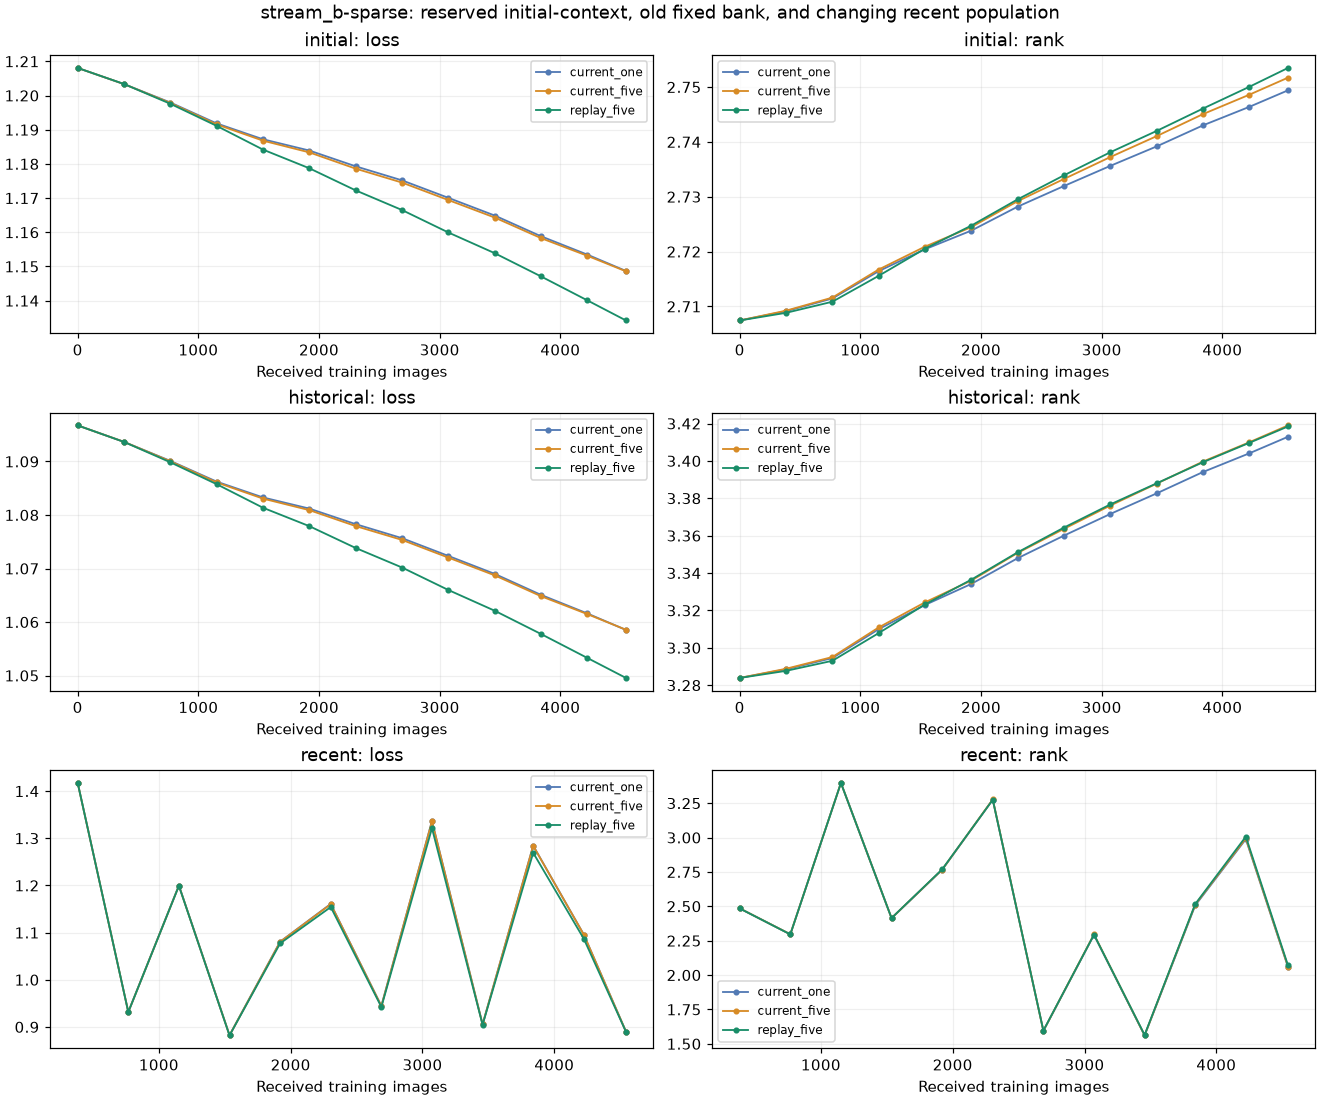

### stream_b / sparse: budgets (completed)
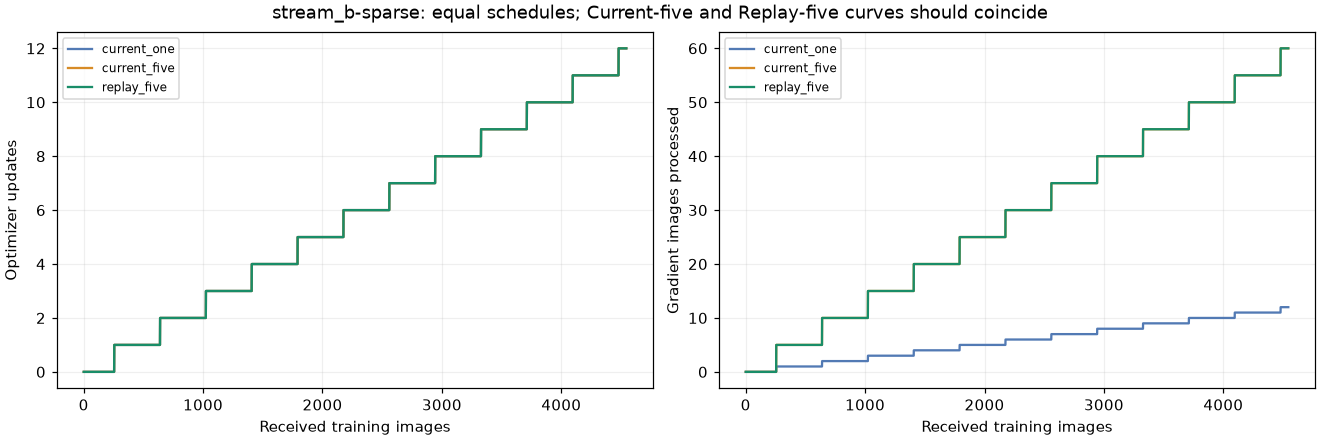

### stream_b / sparse: future-tail (completed)
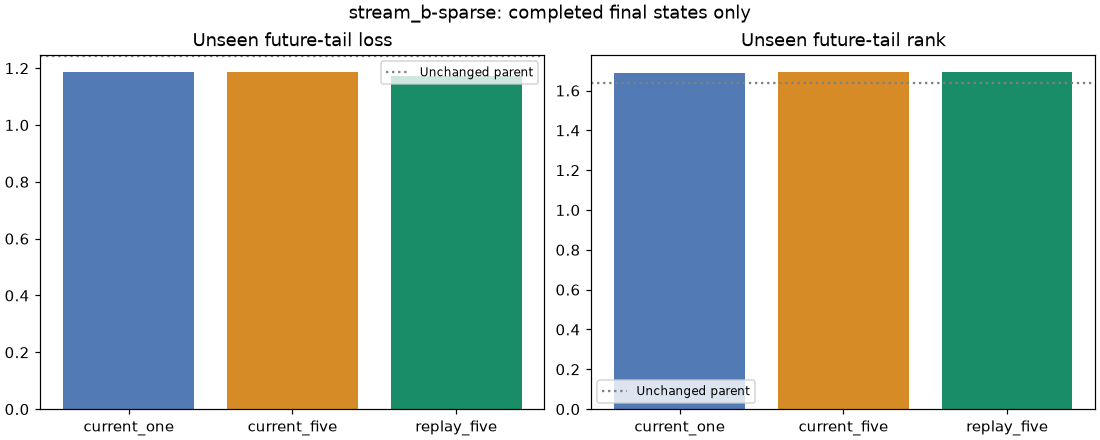

### stream_c / dense: incoming-health (completed)
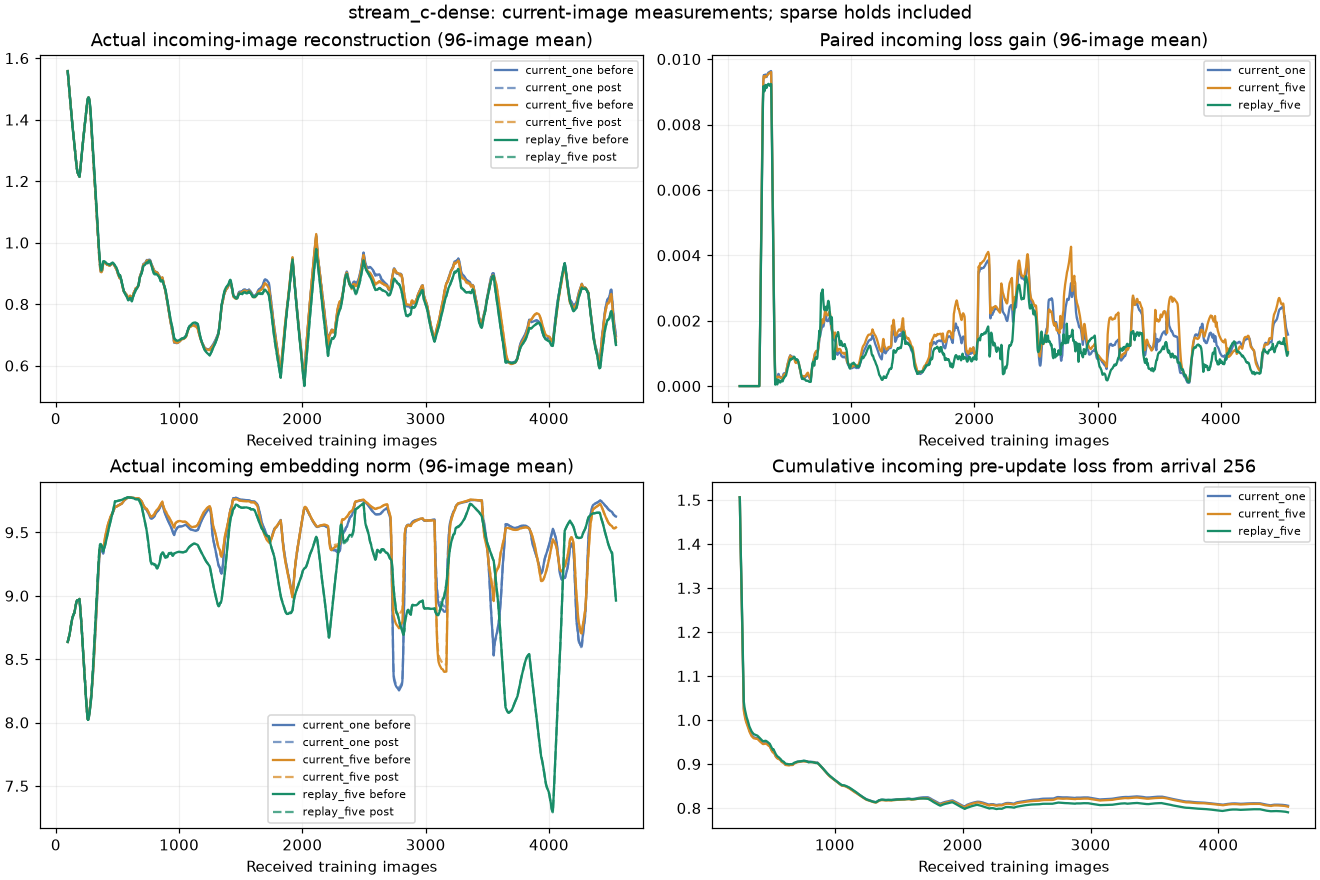

### stream_c / dense: audit-health (completed)
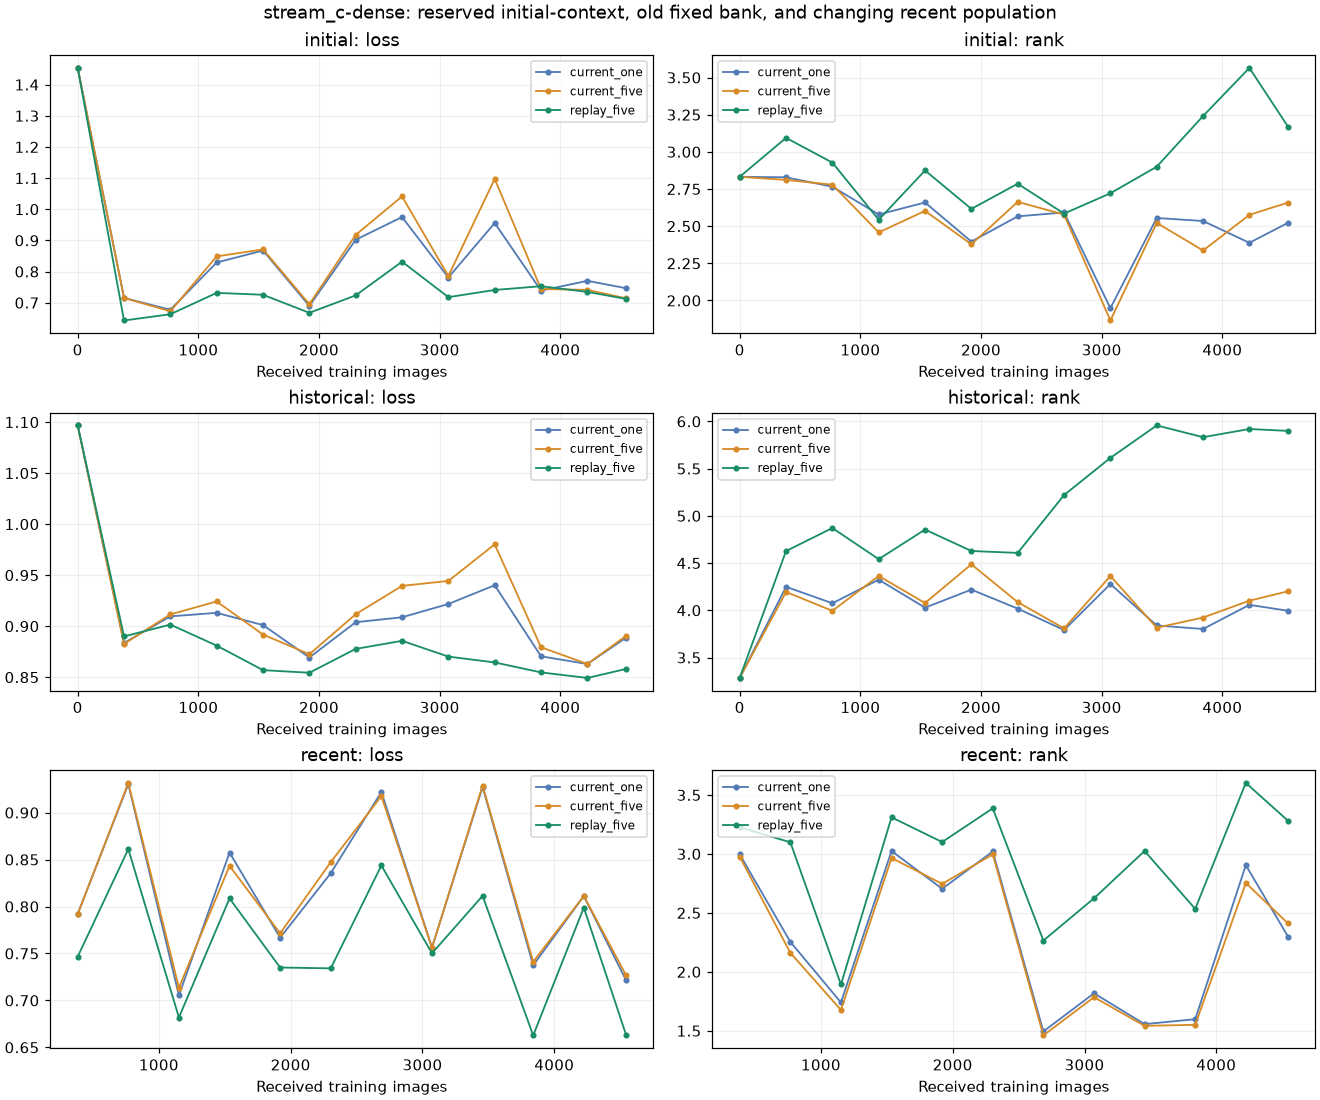

### stream_c / dense: budgets (completed)
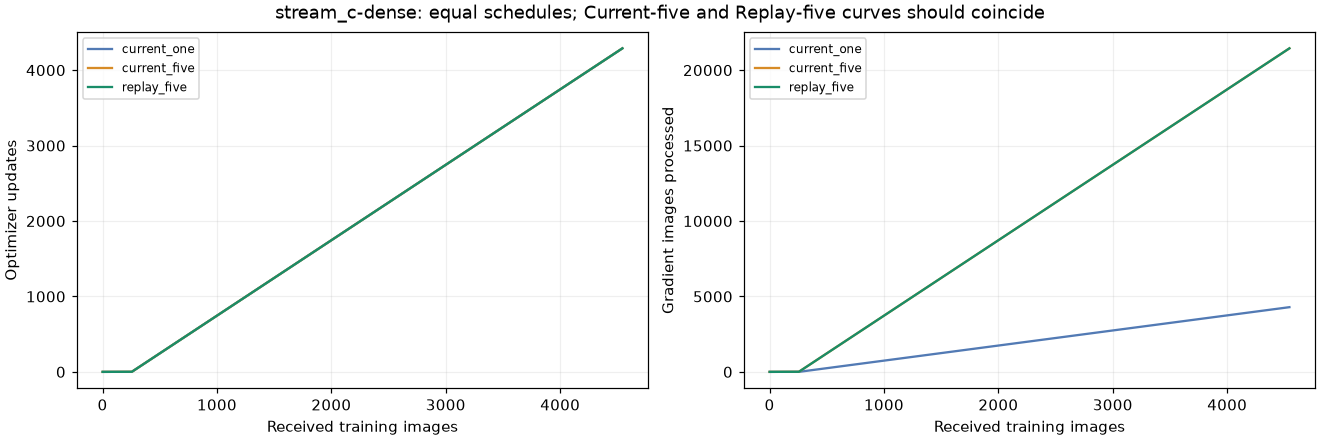

### stream_c / dense: future-tail (completed)
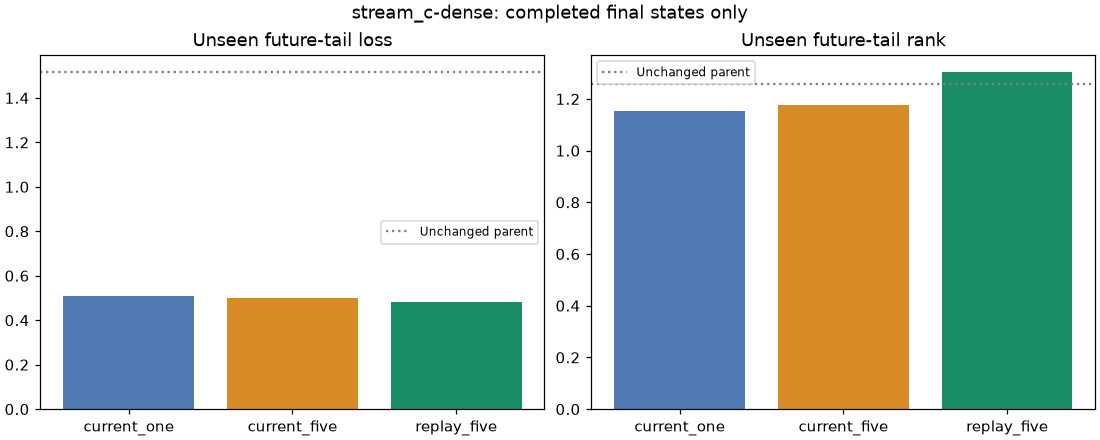